# Chapter 12 — Seaborn: Statistical Data Visualization

Seaborn builds statistical graphics on Matplotlib with high-level functions, semantic mappings, statistical estimators, and attractive defaults.

## Prerequisites
Pandas DataFrames and basic Matplotlib; install Seaborn.

## Learning goals
- Understand long-form and wide-form data.
- Use axes-level and figure-level plotting functions.
- Create distribution, relational, categorical, and matrix plots.
- Interpret hue, facets, estimators, and confidence intervals.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Chapter map

1. Data model and semantics
2. Relational plots
3. Distribution plots
4. Categorical plots
5. Heatmaps, pair plots, facets

### Data model and semantics
Seaborn supports long and wide data; long form is usually clearer. Map with `data`, `x`, `y`, `hue`, `style`, and `size`. `hue` encodes categorical color, `style` marker/line type, and `size` a quantitative channel. Axes-level functions draw on a Matplotlib Axes (`scatterplot`, `histplot`, `boxplot`); figure-level functions manage grids (`relplot`, `displot`, `catplot`, `pairplot`).

#### Demonstration 1 — Set a theme and plot distributions

Run the code and inspect both the output and the assumptions behind it.

Data directory: /mnt/data/python_data_analysis_book/data


/mnt/data/python_data_analysis_book/Chapter_12_seaborn_statistical_data_visualization/Chapter_12_Concepts_and_Theory.ipynb:8: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



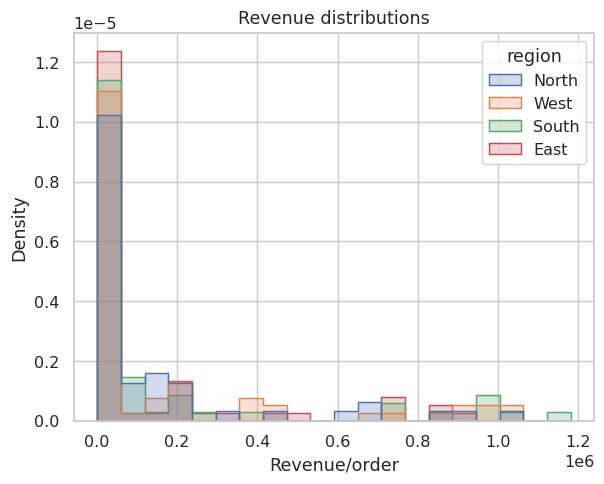

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
sales=pd.read_csv(DATA/"sales.csv"); sns.set_theme(style="whitegrid",context="notebook")
ax=sns.histplot(data=sales,x="revenue",hue="region",bins=20,element="step",stat="density",common_norm=False); ax.set(title="Revenue distributions",xlabel="Revenue/order"); plt.show()

### Relational plots
`scatterplot(data,x,y,hue,style,size,alpha,...)` maps pairs. `lineplot` aggregates repeated observations by default and may show uncertainty; set `estimator=None` for raw lines. Confidence intervals around an estimate express uncertainty in an estimated statistic, not the range of individual values.

#### Demonstration 2 — Show a relationship with hue

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_12_seaborn_statistical_data_visualization/Chapter_12_Concepts_and_Theory.ipynb:1: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



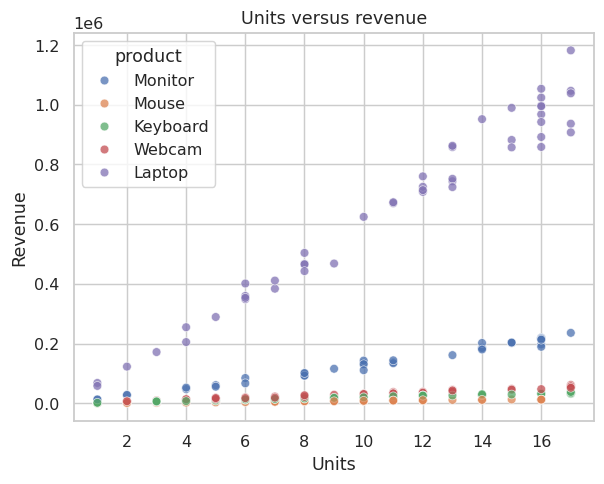

In [3]:
ax=sns.scatterplot(data=sales,x="units",y="revenue",hue="product",alpha=.75); ax.set(title="Units versus revenue",xlabel="Units",ylabel="Revenue"); plt.show()

### Distribution plots
`histplot(data,x,bins="auto",stat="count",kde=False,...)` displays binned values. `kdeplot` estimates smooth density; bandwidth affects shape. `ecdfplot` shows the empirical cumulative distribution. `stat="density"` normalizes area rather than counts. Use consistent bins/scales for comparisons.

#### Demonstration 3 — Compare category distributions

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_12_seaborn_statistical_data_visualization/Chapter_12_Concepts_and_Theory.ipynb:1: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



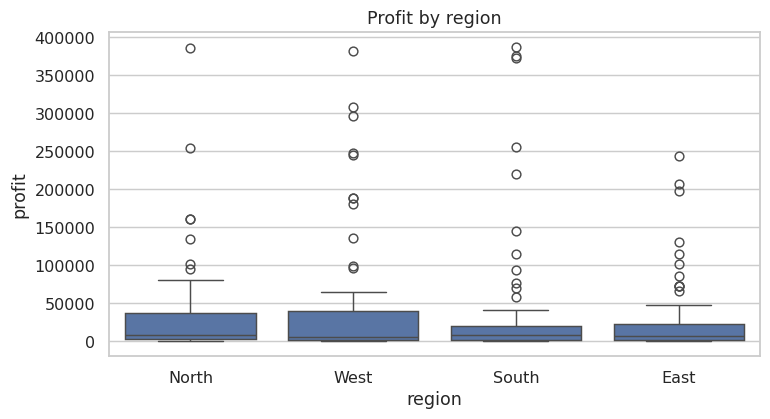

In [4]:
fig,ax=plt.subplots(figsize=(8,4)); sns.boxplot(data=sales,x="region",y="profit",ax=ax); ax.set_title("Profit by region"); plt.show()

### Categorical plots
`barplot` estimates a statistic (mean by default); `countplot` counts observations. `boxplot` shows quartiles and whisker rules (`whis`); `violinplot` adds density; `stripplot`/`swarmplot` show observations. A mean bar is not a raw count. Consider median and spread where distributions are skewed.

#### Demonstration 4 — Understand mean versus count

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_12_seaborn_statistical_data_visualization/Chapter_12_Concepts_and_Theory.ipynb:1: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



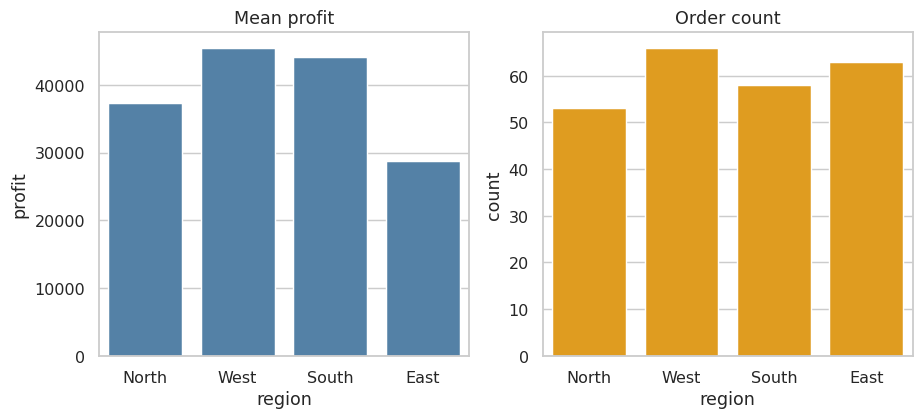

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4)); sns.barplot(data=sales,x="region",y="profit",errorbar=None,color="steelblue",ax=axes[0]); sns.countplot(data=sales,x="region",color="orange",ax=axes[1]); axes[0].set_title("Mean profit"); axes[1].set_title("Order count"); plt.show()

### Heatmaps, pair plots, facets
`heatmap(data,annot,fmt,cmap,center,vmin,vmax)` maps matrix values to color. Correlation heatmaps show linear association, not causation. `pairplot(data,hue,vars,diag_kind)` can be expensive with many columns. Figure-level plots support row/column facets for small multiples.

#### Demonstration 5 — Build a correlation heatmap

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_12_seaborn_statistical_data_visualization/Chapter_12_Concepts_and_Theory.ipynb:1: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



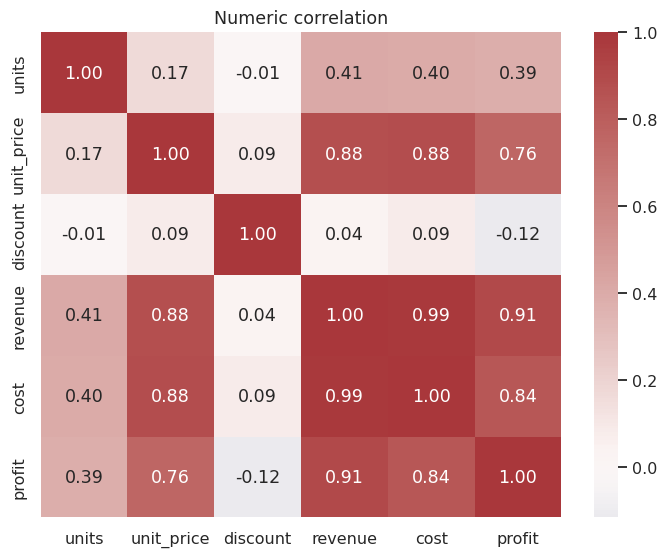

In [6]:
corr=sales.select_dtypes(include="number").corr(); fig,ax=plt.subplots(figsize=(8,6)); sns.heatmap(corr,annot=True,fmt=".2f",center=0,cmap="vlag",ax=ax); ax.set_title("Numeric correlation"); plt.show()

## Self-check

Without looking back, explain the key terms, identify the important parameters, describe at least one alternative or variation, and state one limitation of the methods covered. Then answer the exercises below.

### Review questions

- Explain one important concept from: Data model and semantics.
- Explain one important concept from: Relational plots.
- Explain one important concept from: Distribution plots.
- Explain one important concept from: Categorical plots.
- Explain one important concept from: Heatmaps, pair plots, facets.